In [26]:
import pandas as pd

df = pd.read_csv("../archive/creditcard.csv")

print(df.shape)
print(df.head())
print(df.info())

(284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V

In [27]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [28]:
df["Class"].value_counts(normalize=True)*100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

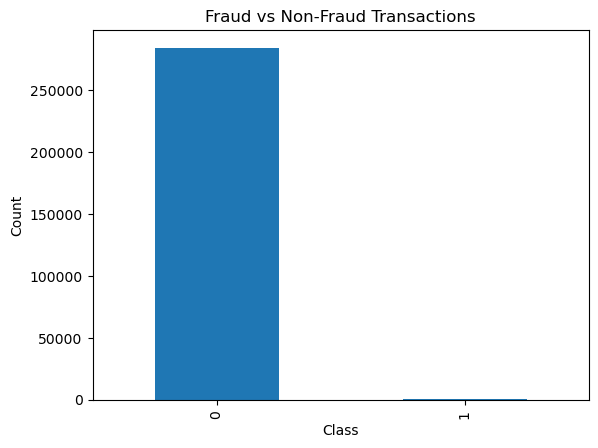

In [29]:
import matplotlib.pyplot as plt

df["Class"].value_counts().plot(kind="bar")

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [30]:
df["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [31]:
df["Time"].describe()

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64

In [32]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


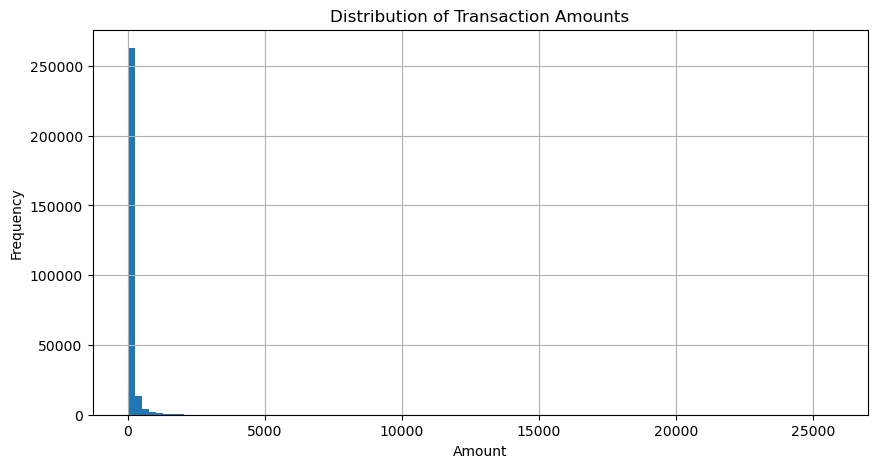

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

df["Amount"].hist(bins=100)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Amount")
plt.ylabel("Frequency")

plt.savefig("Amounts_Distribution.png", bbox_inches="tight")
plt.show()

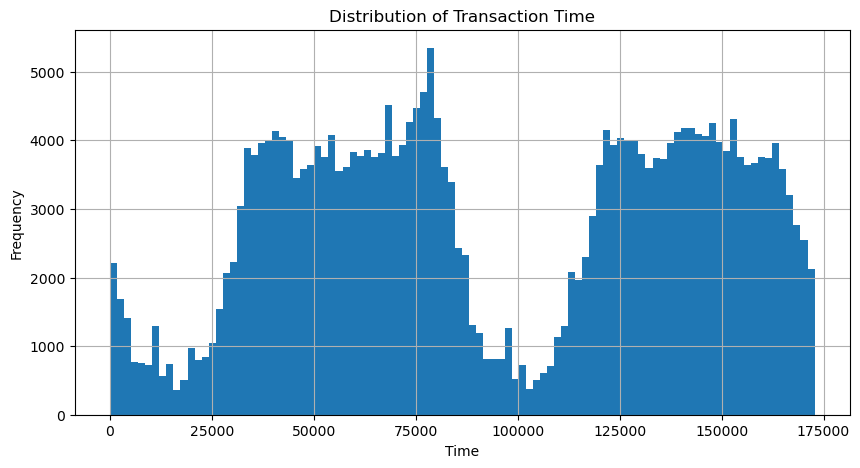

In [34]:
plt.figure(figsize=(10,5))

df["Time"].hist(bins=100)

plt.title("Distribution of Transaction Time")
plt.xlabel("Time")
plt.ylabel("Frequency")
plt.savefig("Time_Distribution.png", bbox_inches="tight")

plt.show()

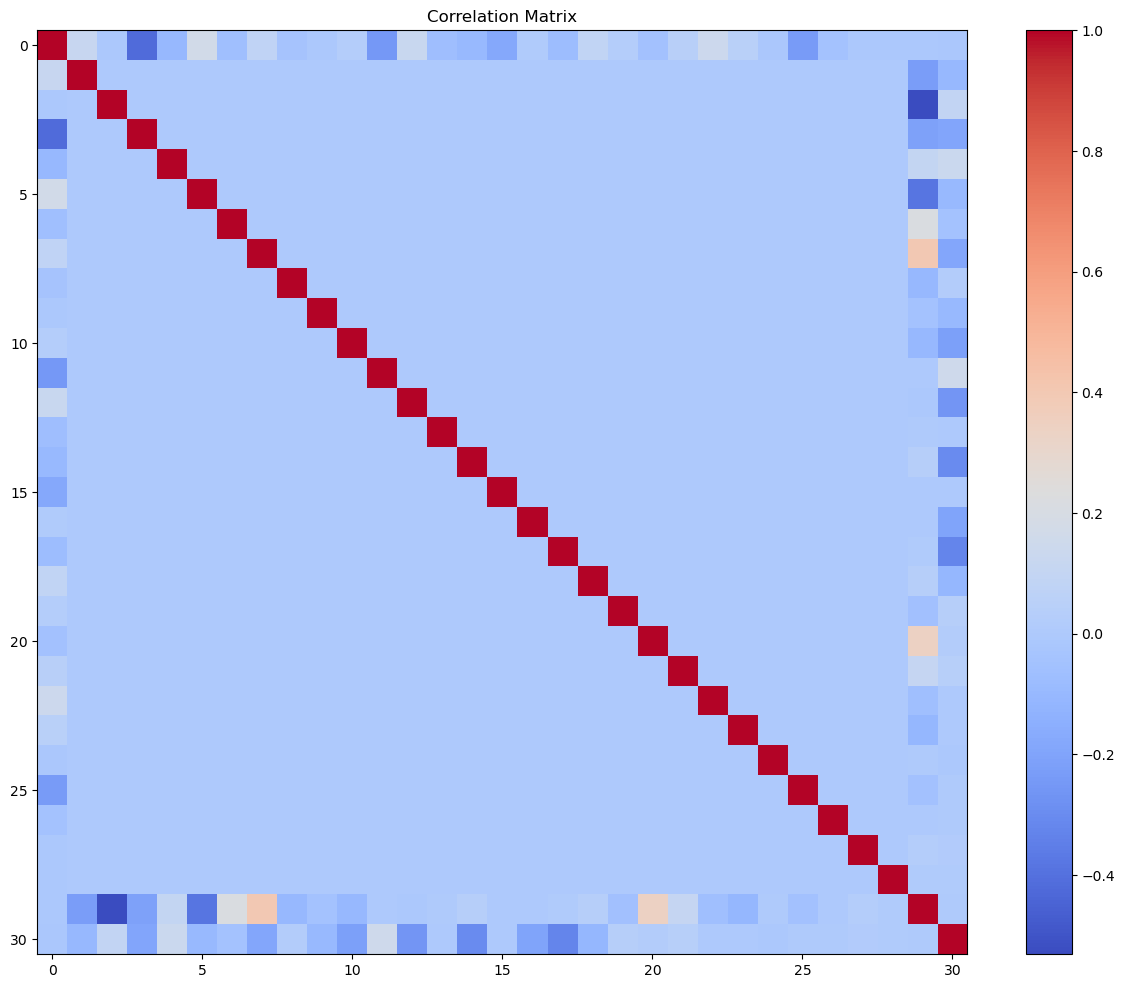

In [35]:
import matplotlib.pyplot as plt
# Full correlation matrix for general exploration
corr = df.corr()

plt.figure(figsize=(15,12))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.title("Correlation Matrix")
plt.show()


In [36]:
df.corr()["Class"].sort_values(ascending=False)

Class     1.000000
V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64

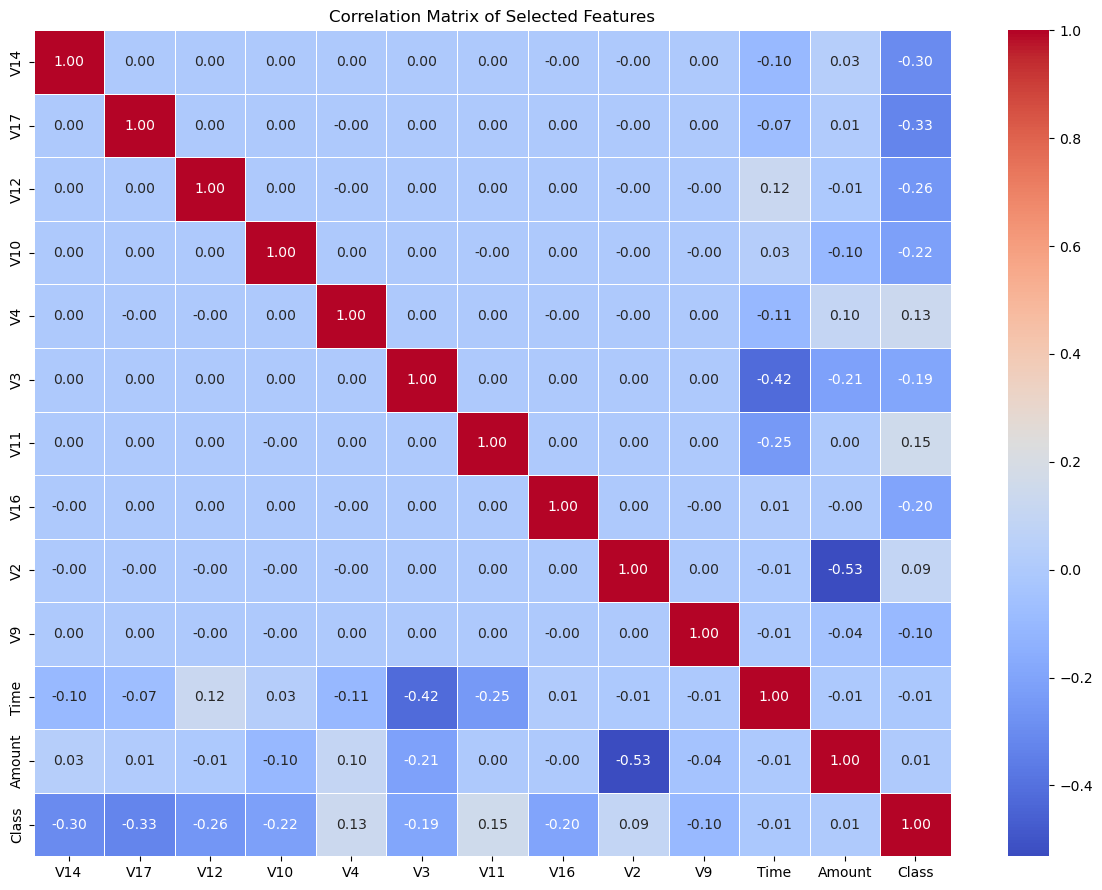

In [37]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create img folder if it does not exist
os.makedirs("img", exist_ok=True)

# Select the most relevant variables for the correlation matrix
selected_features = [
    "V14", "V17", "V12", "V10", "V4",
    "V3", "V11", "V16", "V2", "V9",
    "Time", "Amount", "Class"
]

# Compute correlation matrix
correlation_matrix = df[selected_features].corr()

# Plot correlation matrix
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix of Selected Features")
plt.tight_layout()

# Save the figure in the img folder
plt.savefig("img/Correlation_Matrix.png", dpi=300, bbox_inches="tight")

plt.show()

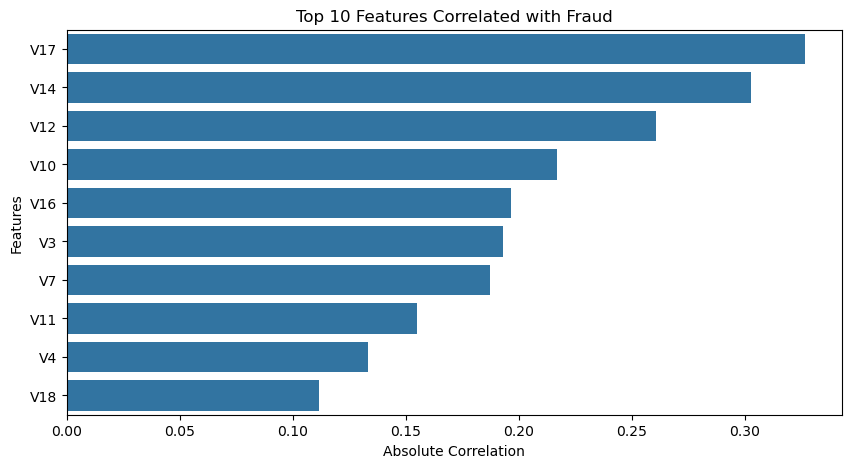

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

top_corr = df.corr()["Class"].drop("Class").abs().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_corr.values, y=top_corr.index)

plt.title("Top 10 Features Correlated with Fraud")
plt.xlabel("Absolute Correlation")
plt.ylabel("Features")

plt.show()


In [39]:
X = df.drop("Class", axis=1)
y = df["Class"]

print(X.shape)
print(y.shape)

(284807, 30)
(284807,)


In [40]:
from sklearn.model_selection import train_test_split

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (227845, 30)
X_test  : (56962, 30)
y_train : (227845,)
y_test  : (56962,)


In [42]:
print(y_train.value_counts())
print()
print(y_test.value_counts())

Class
0    227451
1       394
Name: count, dtype: int64

Class
0    56864
1       98
Name: count, dtype: int64


In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time", "Amount"]])
X_test_scaled[["Time", "Amount"]] = scaler.transform(X_test[["Time", "Amount"]])

print(X_train_scaled[["Time", "Amount"]].head())

            Time    Amount
265518  1.411588 -0.322494
180305  0.623141 -0.339764
42664  -1.130680  0.346693
198723  0.794699 -0.327360
82325  -0.748102 -0.008281


In [44]:
from imblearn.over_sampling import SMOTE

In [45]:
smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE :")
print(y_train.value_counts())

print("\nAfterSMOTE :")
print(y_train_resampled.value_counts())
print("\nNote: Class 1 after SMOTE includes the original fraud cases and synthetic samples generated by SMOTE.")

Before SMOTE :
Class
0    227451
1       394
Name: count, dtype: int64

AfterSMOTE :
Class
0    227451
1    227451
Name: count, dtype: int64

Note: Class 1 after SMOTE includes the original fraud cases and synthetic samples generated by SMOTE.


In [46]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    random_state=42,
    max_iter=1000
)

lr.fit(
    X_train_resampled,
    y_train_resampled
)

print("Model trained successfully")

Model trained successfully


In [47]:
y_pred = lr.predict(X_test_scaled)

In [48]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



In [49]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[55403  1461]
 [    8    90]]


In [50]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train_resampled,
    y_train_resampled
)

print("Random Forest trained successfully")

Random Forest trained successfully


In [51]:
y_pred_rf = rf.predict(X_test_scaled)

In [52]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.85      0.84      0.84        98

    accuracy                           1.00     56962
   macro avg       0.92      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [53]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb.fit(
    X_train_resampled,
    y_train_resampled
)

print("XGBoost trained successfully")

XGBoost trained successfully


In [54]:
y_pred_xgb = xgb.predict(X_test_scaled)

In [55]:
    from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.73      0.89      0.80        98

    accuracy                           1.00     56962
   macro avg       0.87      0.94      0.90     56962
weighted avg       1.00      1.00      1.00     56962



In [56]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[56849    15]
 [   16    82]]


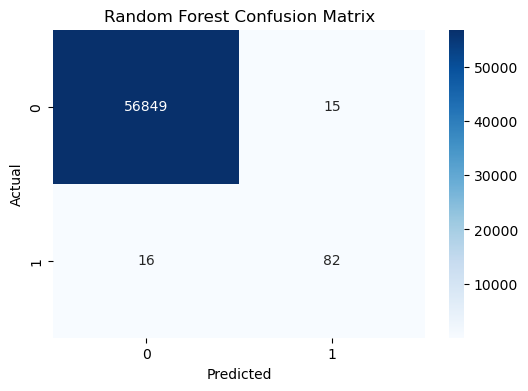

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig("RF_confusion_matrix.png", bbox_inches="tight")

plt.show()

In [58]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

print(cm_xgb)

[[56832    32]
 [   11    87]]


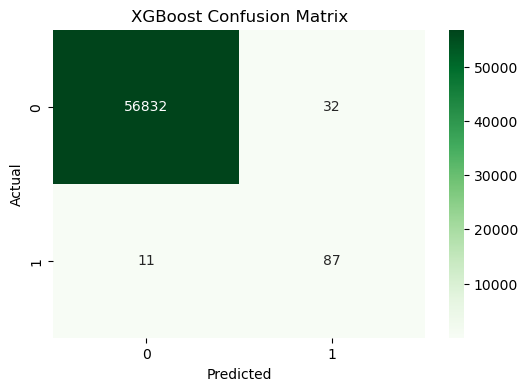

In [59]:
plt.figure(figsize=(6,4))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("XGB_confusion_matrix.png", bbox_inches="tight")

plt.show()

In [60]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(10))

   Feature  Importance
14     V14    0.195592
10     V10    0.110475
4       V4    0.106104
12     V12    0.095099
17     V17    0.085020
3       V3    0.060413
11     V11    0.056353
16     V16    0.043779
2       V2    0.036997
9       V9    0.026209


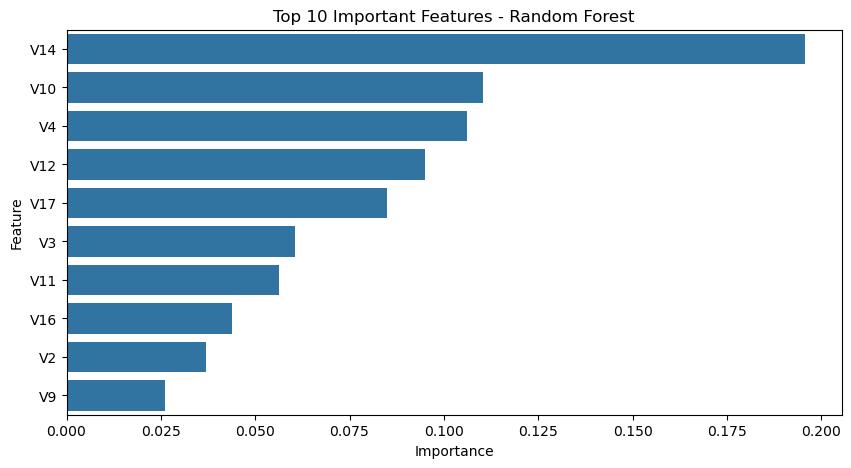

In [61]:
top10 = importance.head(10)

plt.figure(figsize=(10,5))

sns.barplot(
    x="Importance",
    y="Feature",
    data=top10
)

plt.title("Top 10 Important Features - Random Forest")
plt.savefig("Important_Features.png", bbox_inches="tight")

plt.show()

In [62]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "Precision": [0.06, 0.85, 0.73],
    "Recall": [0.92, 0.84, 0.89],
    "F1-Score": [0.11, 0.84, 0.80]
})

print(results)

                 Model  Precision  Recall  F1-Score
0  Logistic Regression       0.06    0.92      0.11
1        Random Forest       0.85    0.84      0.84
2              XGBoost       0.73    0.89      0.80


In [63]:
from sklearn.metrics import roc_curve, auc

y_prob_rf = rf.predict_proba(X_test_scaled)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)

roc_auc = auc(fpr, tpr)

print("AUC =", roc_auc)

AUC = 0.9731024901519414


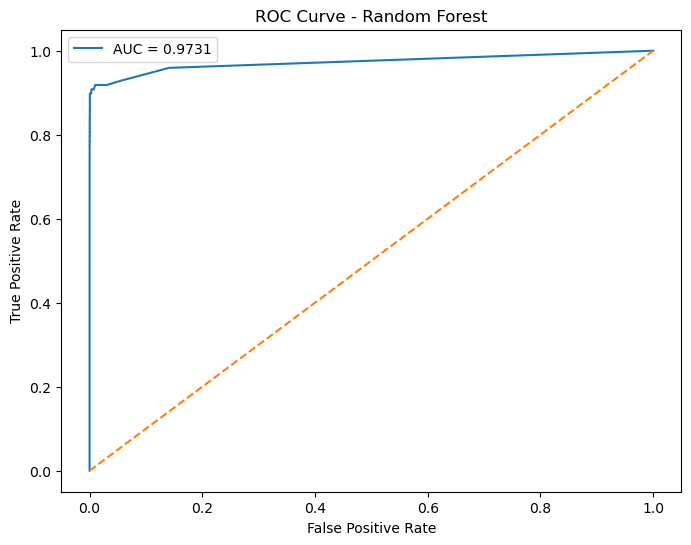

In [64]:
plt.figure(figsize=(8,6))

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()

plt.show()

In [65]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],

    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],

    "F1-Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.974211   0.058027  0.918367  0.109157
1        Random Forest  0.999456   0.845361  0.836735  0.841026
2              XGBoost  0.999245   0.731092  0.887755  0.801843


In [66]:
results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9742,0.0580,0.9184,0.1092
1,Random Forest,0.9995,0.8454,0.8367,0.8410
2,XGBoost,0.9992,0.7311,0.8878,0.8018


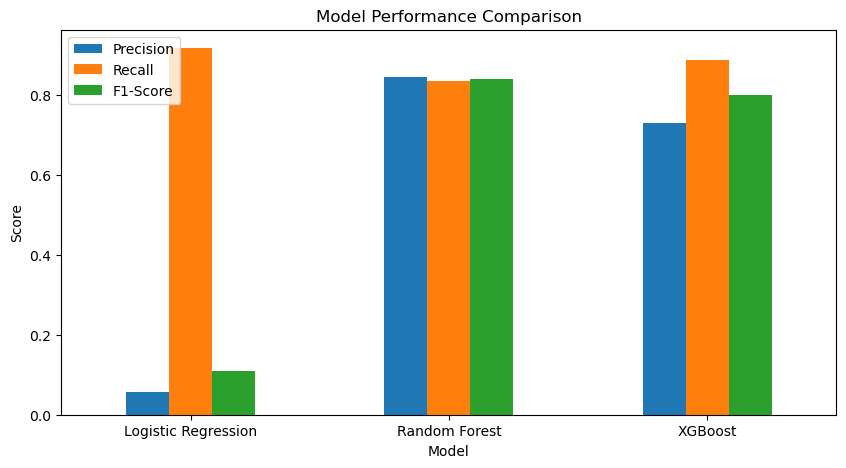

In [67]:
results.set_index("Model")[["Precision","Recall","F1-Score"]].plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()